# M4 · Injured body parts: training notebook

**Goal:** from what the blackbox measures in a crash (+ the user's profile), predict **which body regions are likely injured**, so the hospital's digital twin can show a body map before the patient arrives.

One yes/no question per region: *is there an injury of AIS 2 or more ("moderate", usually needs hospital care) in this region?*

**Steps**
1. Load the training table built by `build_m4_dataset.py` (CISS 2017–23)
2. Choose the inputs (the same as M3)
3. Keep usable rows
4. Split into train / test, by crash
5. Train 4 models per region: our rule, a classic formula, our AI model, and our AI model + seat position
6. Compare them
7. Look at what the model learned
8. Turn the probabilities into a body map
9. Save the model
10. Try it on example crashes

**Kernel:** pick **Python (solvex-m4)** at the top right. Everything runs on a normal PC in about a minute, no GPU needed.

## 1 · Load the data

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import joblib
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
SEED = 42

df = pd.read_csv("data/m4_training.csv", low_memory=False)
groups = json.loads(Path("data/m4_training.columns.json").read_text())

# Neck has only ~60 cases: too few to learn. Neck bones are coded under spine anyway, so we merge.
neck, spine = df["inj_neck"], df["inj_spine"]
df["inj_spine"] = np.where((neck == 1) | (spine == 1), 1.0, np.where((neck == 0) & (spine == 0), 0.0, np.nan))

REGIONS = ["head", "face", "thorax", "abdomen", "spine", "arms", "legs"]
LABELS = [f"inj_{r}" for r in REGIONS]

print(f"Loaded {len(df):,} crash occupants from CISS {df.year.min()}-{df.year.max()}, {df.shape[1]} columns")
print(f"Body regions predicted: {', '.join(REGIONS)} (neck merged into spine)")

Loaded 35,093 crash occupants from CISS 2017-2023, 46 columns
Body regions predicted: head, face, thorax, abdomen, spine, arms, legs (neck merged into spine)


## 2 · Choose the inputs

Same rule as M3: only what we can know at crash time **without the car's own sensors**.

- **Blackbox:** ΔV (speed change), direction of the impact, rollover, multiple impacts
- **App profile:** age, sex, vehicle type

**Why no BMI (unlike M3):** in CISS, height and weight are missing for a third of people, and the missing ones are mostly people who were *not* hurt (investigators get them from hospital records). At the same ΔV, people without BMI have ~4× fewer injuries. A model with BMI learns "BMI recorded = injured", but in our app BMI is always filled in (or never), so it would mislead. Without BMI the ranking loses only ~0.002 AUC on people whose BMI is known.

The direction is given as **sin** and **cos** of the angle, so 359° and 1° are both "front".

**Seat position** matters for body parts: in a side impact, the person sitting on the hit side takes it in the chest and pelvis. The app could ask *"are you driving?"* at the start of a trip, so we train a second model with it: the impact direction seen **from the seat** (near side / far side) and whether the person is in the front row.

In [2]:
for col, angle in [("pdof", "pdof_car"), ("pdof_seat", "pdof_seat")]:
    df[f"{col}_sin"] = np.sin(np.radians(df[angle]))
    df[f"{col}_cos"] = np.cos(np.radians(df[angle]))
for g in ["utility", "van", "pickup"]:           # "car" is the reference type
    df[f"body_{g}"] = (df["body_group"] == g).astype(float)
df["front_row"] = (df["seat_row"] == 1).astype(float).where(df["seat_row"].notna())

FEATURES = {
    "dv_kmh":       "blackbox  speed change during impact (km/h)",
    "pdof_sin":     "blackbox  impact direction, sin part",
    "pdof_cos":     "blackbox  impact direction, cos part",
    "rollover":     "blackbox  car rolled over (1/0)",
    "multi_impact": "blackbox  more than one impact (1/0)",
    "age":          "profile   age (years)",
    "male":         "profile   sex (1 male, 0 female)",
    "body_utility": "profile   vehicle is an SUV (1/0)",
    "body_van":     "profile   vehicle is a van (1/0)",
    "body_pickup":  "profile   vehicle is a pickup (1/0)",
}
SEAT_FEATURES = {
    "pdof_seat_sin": "blackbox + seat  impact direction seen from the seat, sin part (+ = hit on the person's side)",
    "pdof_seat_cos": "blackbox + seat  impact direction seen from the seat, cos part",
    "front_row":     "app       person sits in the front row (1/0)",
}
X_COLS = list(FEATURES)
X_COLS_SEAT = [c for c in X_COLS if not c.startswith("pdof_")] + list(SEAT_FEATURES)

print("Model inputs:")
for col, desc in FEATURES.items():
    print(f"  {col:<14} {desc}")
print("\nSeat model: replaces the car direction by the seat direction, adds:")
for col, desc in SEAT_FEATURES.items():
    print(f"  {col:<14} {desc}")

Model inputs:
  dv_kmh         blackbox  speed change during impact (km/h)
  pdof_sin       blackbox  impact direction, sin part
  pdof_cos       blackbox  impact direction, cos part
  rollover       blackbox  car rolled over (1/0)
  multi_impact   blackbox  more than one impact (1/0)
  age            profile   age (years)
  male           profile   sex (1 male, 0 female)
  body_utility   profile   vehicle is an SUV (1/0)
  body_van       profile   vehicle is a van (1/0)
  body_pickup    profile   vehicle is a pickup (1/0)

Seat model: replaces the car direction by the seat direction, adds:
  pdof_seat_sin  blackbox + seat  impact direction seen from the seat, sin part (+ = hit on the person's side)
  pdof_seat_cos  blackbox + seat  impact direction seen from the seat, cos part
  front_row      app       person sits in the front row (1/0)


## 3 · Keep usable rows

As in M3: keep rows where the database has ΔV, impact direction, age and sex (the blackbox always measures the first two; a missing value in the database is not random, see M3). A region whose label is unknown (an injury there of unknown severity) is skipped for that region only.

In [3]:
data = df[df["dv_kmh"].notna() & df["pdof_car"].notna() & df["age"].notna() & df["male"].notna()].copy()
data["case"] = data["key"].str.rsplit("_", n=2).str[0]   # crash id = key without vehicle and occupant
any_injury = (data[LABELS] == 1).any(axis=1)

print(f"Rows before: {len(df):,}")
print(f"Rows kept:   {len(data):,}  (others have no delta-V, direction, age or sex)")
print(f"Crashes:     {data['case'].nunique():,}")
print(f"People with at least one injured region: {any_injury.sum():,} = {any_injury.mean():.1%}")
print("\nInjured people per region:")
summary = pd.DataFrame({
    "injured": data[LABELS].sum().astype(int).values,
    "share": (data[LABELS].mean() * 100).round(1).astype(str).add(" %").values,
    "unknown": data[LABELS].isna().sum().values,
}, index=REGIONS)
print(summary.to_string())

Rows before: 35,093
Rows kept:   18,297  (others have no delta-V, direction, age or sex)
Crashes:     9,301
People with at least one injured region: 2,940 = 16.1%

Injured people per region:
         injured  share  unknown
head         935  5.2 %      328
face         243  1.3 %        1
thorax      1181  6.5 %       22
abdomen      501  2.7 %       18
spine        600  3.3 %       23
arms         830  4.5 %        7
legs        1118  6.1 %        6


## 4 · Split into train and test, by crash

Same split as M3: **train 64 %**, **validation 16 %** (to stop training and choose thresholds), **test 20 %** (never seen until the end). By crash, so two people from the same car never end up on both sides.

In [4]:
def split_by_crash(frame, test_size, seed):
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
                .split(frame, groups=frame["case"]))
    return frame.iloc[a], frame.iloc[b]

train_full, test = split_by_crash(data, 0.20, SEED)
train, valid = split_by_crash(train_full, 0.20, SEED)

counts = pd.DataFrame({name: part[LABELS].sum().astype(int).values
                       for name, part in [("train", train), ("validation", valid), ("test", test)]},
                      index=REGIONS)
for name, part in [("train", train), ("validation", valid), ("test", test)]:
    print(f"{name:<11} {len(part):>6,} people  {part['case'].nunique():>6,} crashes")
print("\nInjured people per region in each part:")
print(counts.to_string())
assert not set(train["case"]) & set(test["case"]), "a crash is in both train and test"
print("\nNo crash appears in both train and test ✓")

train       11,717 people   5,952 crashes
validation   2,919 people   1,488 crashes
test         3,661 people   1,861 crashes

Injured people per region in each part:
         train  validation  test
head       618         136   181
face       167          33    43
thorax     774         191   216
abdomen    340          62    99
spine      403          86   111
arms       536         143   151
legs       756         164   198

No crash appears in both train and test ✓


## 5 · Train the models

One model **per region** (7 yes/no questions). A person can have several injured regions at once, so each region gets its own model.

| Model | What it is | Why |
|---|---|---|
| **A · Our rule** | the fallback rule from our plan: ΔV, counted fully for the regions the impact type usually injures | the baseline if AI fails |
| **B · Classic formula** | logistic regression on all inputs | how Weaver et al. 2015 build region risk curves |
| **C · Our AI model** | LightGBM, same settings as M3 | learns curves and interactions (side impact × chest, rollover × head) |
| **D · AI + seat** | same as C, direction seen from the seat + front row | measures what *"are you driving?"* is worth |

**Rule A:** front → head, thorax, legs, arms · side → thorax, legs (pelvis), head, abdomen · rear → spine · rollover → head, spine. Score = ΔV for expected regions, ΔV × 0.3 for the others, + 100 when the rule's rollover regions match.

As in M3, the AI model's risk can **never go down when ΔV goes up**.

In [5]:
RULE = {
    "front": {"head", "thorax", "legs", "arms"},
    "left":  {"thorax", "legs", "head", "abdomen"},
    "right": {"thorax", "legs", "head", "abdomen"},
    "rear":  {"spine"},
}
ROLLOVER_REGIONS = {"head", "spine"}

def rule_score(frame, region):
    expected = frame["direction_car"].map(lambda d: region in RULE.get(d, set()))
    score = frame["dv_kmh"] * np.where(expected, 1.0, 0.3)
    if region in ROLLOVER_REGIONS:
        score = score + 100 * frame["rollover"].fillna(0)
    return score.values

LGB_PARAMS = dict(
    n_estimators=2000, learning_rate=0.03, num_leaves=15, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
    random_state=SEED, verbose=-1,
)

def known(frame, label):
    return frame[frame[label].notna()]

def train_lgbm(cols, label):
    tr, va = known(train, label), known(valid, label)
    model = lgb.LGBMClassifier(**LGB_PARAMS, monotone_constraints=[1 if c == "dv_kmh" else 0 for c in cols])
    model.fit(tr[cols], tr[label], eval_set=[(va[cols], va[label])], eval_metric="auc",
              callbacks=[lgb.early_stopping(100, verbose=False)])
    return model

models_b, models_c, models_d = {}, {}, {}
print(f"{'region':<9} {'B weights: top 3 inputs':<48} {'C trees':>8} {'D trees':>8}")
for region, label in zip(REGIONS, LABELS):
    tr = known(train, label)
    models_b[region] = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                     LogisticRegression(max_iter=1000)).fit(tr[X_COLS], tr[label])
    models_c[region] = train_lgbm(X_COLS, label)
    models_d[region] = train_lgbm(X_COLS_SEAT, label)
    w = sorted(zip(X_COLS, models_b[region][-1].coef_[0]), key=lambda t: -abs(t[1]))[:3]
    top = ", ".join(f"{c} {v:+.2f}" for c, v in w)
    print(f"{region:<9} {top:<48} {models_c[region].best_iteration_:>8} {models_d[region].best_iteration_:>8}")

region    B weights: top 3 inputs                           C trees  D trees


head      dv_kmh +0.60, multi_impact +0.29, rollover +0.24      137      130


face      dv_kmh +0.50, multi_impact +0.48, pdof_cos +0.21      102       88


thorax    dv_kmh +0.97, age +0.75, multi_impact +0.34           157      154


abdomen   dv_kmh +0.97, age +0.28, rollover +0.22                17       32


spine     dv_kmh +0.70, age +0.63, multi_impact +0.45            77      111


arms      dv_kmh +0.62, age +0.35, pdof_cos +0.30               187      180


legs      dv_kmh +0.98, pdof_cos +0.45, age +0.39               178      160


## 6 · Compare the models on the test set

- **AUC** per region: pick one person injured in that region and one not; AUC is the chance the model ranks the injured one higher. 0.5 = coin flip. For reference, Weaver et al. and the AACN papers report about **0.75–0.90** per region, using belt and crash details we don't have.
- **AP** (average precision): better for rare regions; a coin flip scores the region's base rate, shown in the last column.
- **Top-2 hit**: among injured people, how often one of the model's 2 highest-risk regions is really injured. This is what the hospital sees first on the body map.

AUC per region (test set)
         A · Our rule  B · Classic formula  C · Our AI model  D · AI + seat
head            0.720                0.779             0.774          0.772
face            0.726                0.794             0.824          0.822
thorax          0.805                0.862             0.867          0.872
abdomen         0.817                0.862             0.879          0.872
spine           0.731                0.814             0.816          0.819
arms            0.703                0.791             0.775          0.775
legs            0.825                0.847             0.856          0.856
mean            0.761                0.821             0.827          0.827

Average precision per region (test set)
         A · Our rule  B · Classic formula  C · Our AI model  D · AI + seat  coin flip
head            0.132                0.191             0.183          0.181      0.050
face            0.045                0.031             0.044          0.046

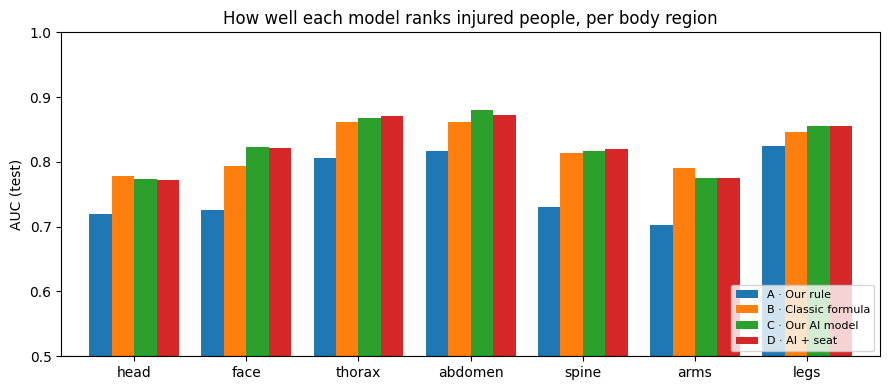

In [6]:
def predict_all(frame, kind):
    out = {}
    for region in REGIONS:
        if kind == "A":
            out[region] = rule_score(frame, region)
        elif kind == "B":
            out[region] = models_b[region].predict_proba(frame[X_COLS])[:, 1]
        elif kind == "C":
            out[region] = models_c[region].predict_proba(frame[X_COLS])[:, 1]
        else:
            out[region] = models_d[region].predict_proba(frame[X_COLS_SEAT])[:, 1]
    return pd.DataFrame(out, index=frame.index)

NAMES = {"A": "A · Our rule", "B": "B · Classic formula", "C": "C · Our AI model", "D": "D · AI + seat"}
test_probs = {k: predict_all(test, k) for k in NAMES}

auc, ap = {}, {}
for k, name in NAMES.items():
    auc[name], ap[name] = {}, {}
    for region, label in zip(REGIONS, LABELS):
        m = test[label].notna()
        auc[name][region] = roc_auc_score(test.loc[m, label], test_probs[k].loc[m, region])
        ap[name][region] = average_precision_score(test.loc[m, label], test_probs[k].loc[m, region])
auc, ap = pd.DataFrame(auc), pd.DataFrame(ap)
auc.loc["mean"] = auc.mean()
ap["coin flip"] = test[LABELS].mean().values
ap.loc["mean"] = ap.mean()

def top2_hit(probs):
    injured = (test[LABELS] == 1).values
    has = injured.any(axis=1)
    if probs.isna().all().all():
        return np.nan
    top2 = np.argsort(-probs.values, axis=1)[:, :2]
    hit = np.take_along_axis(injured, top2, axis=1).any(axis=1)
    return hit[has].mean()

# With random order, the chance that one of 2 regions picked at random is injured:
injured = (test[LABELS] == 1).values
k_inj = injured[injured.any(axis=1)].sum(axis=1)
n = len(REGIONS)
random_top2 = np.mean(1 - (n - k_inj) * (n - k_inj - 1) / (n * (n - 1)))

print("AUC per region (test set)")
print(auc.round(3).to_string())
print("\nAverage precision per region (test set)")
print(ap.round(3).to_string())
print("\nTop-2 hit rate among injured people:")
for k, name in NAMES.items():
    print(f"  {name:<20} {top2_hit(test_probs[k]):.1%}")
print(f"  {'random order':<20} {random_top2:.1%}")

fig, ax = plt.subplots(figsize=(9, 4))
auc.drop("mean").plot.bar(ax=ax, width=0.8)
ax.axhline(0.5, color="k", ls="--", lw=0.8)
ax.set_ylim(0.5, 1)
ax.set_ylabel("AUC (test)")
ax.set_title("How well each model ranks injured people, per body region")
ax.legend(fontsize=8, loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7 · What the AI model learned

**Importance:** which inputs each region's model relies on.

**Body map per crash type:** we invent a 35-year-old man (car) in different crashes at ΔV 45 km/h and ask the model. The pattern should look like the papers: frontal → chest and legs; side → chest, abdomen, head; rollover → head and spine; rear → low everywhere.

Share of each region model's decisions explained by each input (%):
              head  face  thorax  abdomen  spine  arms  legs
dv_kmh          47    38      54       84     47    43    62
pdof_sin        10     8       4        3      4     7     4
pdof_cos         6    11       7        4      3    10     9
rollover         9     6       4        2      5     4     1
multi_impact    10    11       6        2     15     5     5
age             14    23      23        5     23    24    15
male             2     2       1        0      1     4     2
body_utility     1     1       1        0      1     1     1
body_van         0     0       0        0      1     0     0
body_pickup      1     1       0        0      1     1     1


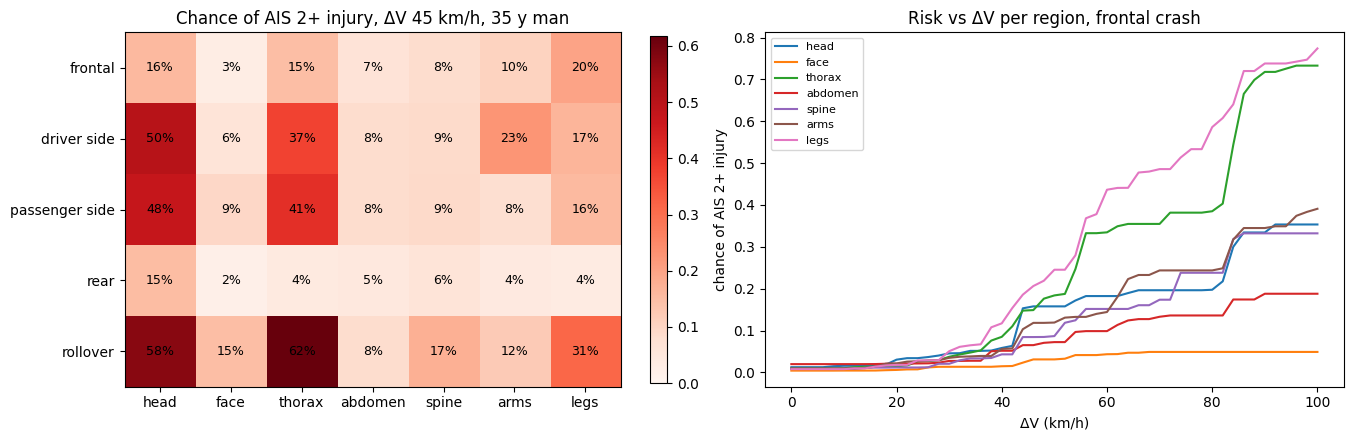

In [7]:
imp = pd.DataFrame({r: models_c[r].booster_.feature_importance("gain") for r in REGIONS}, index=X_COLS)
imp = imp / imp.sum() * 100
print("Share of each region model's decisions explained by each input (%):")
print(imp.round(0).astype(int).to_string())

def scenario(dv, angle=0, age=35, male=1, rollover=0, multi=0):
    dv = np.atleast_1d(np.asarray(dv, dtype=float))
    return pd.DataFrame({
        "dv_kmh": dv, "pdof_sin": np.sin(np.radians(angle)), "pdof_cos": np.cos(np.radians(angle)),
        "rollover": float(rollover), "multi_impact": float(multi), "age": float(age), "male": float(male),
        "body_utility": 0.0, "body_van": 0.0, "body_pickup": 0.0,
    })[X_COLS]

CRASHES = {
    "frontal": dict(angle=0), "driver side": dict(angle=270), "passenger side": dict(angle=90),
    "rear": dict(angle=180), "rollover": dict(angle=90, rollover=1, multi=1),
}
body_map = pd.DataFrame({name: {r: models_c[r].predict_proba(scenario(45, **kw))[0, 1] for r in REGIONS}
                         for name, kw in CRASHES.items()}).T

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
im = axes[0].imshow(body_map.values, cmap="Reds", vmin=0, vmax=max(0.3, body_map.values.max()))
axes[0].set_xticks(range(len(REGIONS)), REGIONS)
axes[0].set_yticks(range(len(CRASHES)), CRASHES)
for i in range(body_map.shape[0]):
    for j in range(body_map.shape[1]):
        axes[0].text(j, i, f"{body_map.iat[i, j]:.0%}", ha="center", va="center", fontsize=9)
axes[0].set_title("Chance of AIS 2+ injury, ΔV 45 km/h, 35 y man")
fig.colorbar(im, ax=axes[0], fraction=0.03)

dv = np.arange(0, 101, 2, dtype=float)
for r in REGIONS:
    axes[1].plot(dv, models_c[r].predict_proba(scenario(dv))[:, 1], label=r)
axes[1].set_xlabel("ΔV (km/h)")
axes[1].set_ylabel("chance of AIS 2+ injury")
axes[1].set_title("Risk vs ΔV per region, frontal crash")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8 · From probabilities to a body map

The hospital twin colours each region in 3 states. Thresholds are picked **per region on the validation set**:

| State | Rule | Meaning for the hospital |
|---|---|---|
| **likely** (red) | chance ≥ 50 %, or the line where half the flagged people are really injured | prepare for it |
| **check** (orange) | above the line that catches **80 %** of injuries in that region | examine first |
| **unlikely** (grey) | below that | no sign from the crash |

Then we check on the test set how often each state is right.

In [8]:
def precision_line(y, p, target=0.5):
    # Lowest threshold where at least `target` of the people above it are really injured.
    order = np.argsort(-p)
    prec = np.cumsum(y[order]) / np.arange(1, len(y) + 1)
    ok = np.where(prec >= target)[0]
    ok = ok[ok >= 9]                     # at least 10 people flagged, or the line is noise
    return float(p[order][ok.max()]) if len(ok) else 0.5

THRESHOLDS = {}
for region, label in zip(REGIONS, LABELS):
    va = known(valid, label)
    y, p = va[label].values, models_c[region].predict_proba(va[X_COLS])[:, 1]
    check = float(np.quantile(p[y == 1], 0.20))      # catches 80 % of injuries
    likely = min(0.5, precision_line(y, p))
    THRESHOLDS[region] = {"check": check, "likely": max(likely, check)}

STATES = ["unlikely", "check", "likely"]
def to_state(p, region):
    t = THRESHOLDS[region]
    return np.select([p >= t["likely"], p >= t["check"]], ["likely", "check"], default="unlikely")

rows = []
for region, label in zip(REGIONS, LABELS):
    m = test[label].notna()
    y, p = test.loc[m, label].values, test_probs["C"].loc[m, region].values
    s = to_state(p, region)
    rows.append({
        "region": region,
        "check from": f"{THRESHOLDS[region]['check']:.1%}",
        "likely from": f"{THRESHOLDS[region]['likely']:.1%}",
        "injuries caught (check+likely)": f"{(s[y == 1] != 'unlikely').mean():.0%}",
        "uninjured flagged": f"{(s[y == 0] != 'unlikely').mean():.0%}",
        "'likely' correct": f"{y[s == 'likely'].mean():.0%}" if (s == "likely").any() else "-",
        "people 'likely'": int((s == "likely").sum()),
    })
print("Test set, per region:")
print(pd.DataFrame(rows).set_index("region").to_string())

Test set, per region:
        check from likely from injuries caught (check+likely) uninjured flagged 'likely' correct  people 'likely'
region                                                                                                           
head          4.1%       50.0%                            72%               33%              33%                6
face          1.2%       50.0%                            81%               28%                -                0
thorax        6.8%       42.1%                            75%               20%              54%               87
abdomen       3.7%       13.4%                            65%               10%              39%               28
spine         4.0%       50.0%                            66%               20%                -                0
arms          3.4%       37.6%                            77%               36%              31%               16
legs          5.5%       39.7%                            80%     

## 9 · Save the model

The 7 region models (C) in one file, plus the input list, thresholds and test scores. The backend's AI API loads these two files, like M3.

In [9]:
out = Path("models")
out.mkdir(exist_ok=True)
joblib.dump(models_c, out / "m4_lgbm.joblib")
config = {
    "features": X_COLS,
    "feature_notes": FEATURES,
    "regions": REGIONS,
    "thresholds": THRESHOLDS,
    "states": STATES,
    "target": "per region: P(AIS 2+ injury), trained unweighted on CISS 2017-23; neck merged into spine",
    "test_auc": auc["C · Our AI model"].round(4).to_dict(),
    "test_top2_hit": round(float(top2_hit(test_probs["C"])), 4),
    "trees": {r: int(m.best_iteration_) for r, m in models_c.items()},
}
(out / "m4_config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False))
print("Saved:")
for f in sorted(out.iterdir()):
    print(f"  {f}  ({f.stat().st_size / 1024:.0f} KB)")

Saved:
  models/m4_config.json  (2 KB)
  models/m4_lgbm.joblib  (1535 KB)


## 10 · Try it on example crashes

What the backend does when the blackbox reports a crash: build the inputs, ask the 7 models, send the body map to the hospital twin. Same crashes as the M3 notebook.

In [10]:
def predict_body(dv_kmh, direction_deg, age, male, rollover=0, multi_impact=0, vehicle="car"):
    x = pd.DataFrame([{
        "dv_kmh": dv_kmh,
        "pdof_sin": np.sin(np.radians(direction_deg)), "pdof_cos": np.cos(np.radians(direction_deg)),
        "rollover": rollover, "multi_impact": multi_impact, "age": age, "male": male,
        "body_utility": float(vehicle == "utility"), "body_van": float(vehicle == "van"),
        "body_pickup": float(vehicle == "pickup"),
    }])[X_COLS]
    return {r: (p := float(models_c[r].predict_proba(x)[0, 1]), str(to_state(np.array([p]), r)[0]))
            for r in REGIONS}

examples = [
    ("Parking bump, rear, 30 y man",            dict(dv_kmh=8,  direction_deg=180, age=30, male=1)),
    ("City crash, front, 25 y woman",           dict(dv_kmh=25, direction_deg=0,   age=25, male=0)),
    ("RN5 guardrail at 90 km/h, 45 y man",      dict(dv_kmh=55, direction_deg=10,  age=45, male=1, multi_impact=1)),
    ("Hit on the driver door, 68 y man",        dict(dv_kmh=35, direction_deg=270, age=68, male=1)),
    ("Rollover on highway, 40 y woman",         dict(dv_kmh=40, direction_deg=90,  age=40, male=0, rollover=1, multi_impact=1)),
]
MARK = {"likely": "●", "check": "◐", "unlikely": "·"}
print(f"{'crash':<38} " + " ".join(f"{r:>9}" for r in REGIONS))
for name, kw in examples:
    res = predict_body(**kw)
    print(f"{name:<38} " + " ".join(f"{MARK[s]} {p:>6.0%}" for p, s in res.values()))
print("\n● likely   ◐ check   · unlikely")

crash                                       head      face    thorax   abdomen     spine      arms      legs
Parking bump, rear, 30 y man           ·     1% ·     0% ·     0% ·     2% ·     1% ·     0% ·     0%
City crash, front, 25 y woman          ·     3% ·     1% ·     1% ·     2% ·     1% ·     3% ·     3%
RN5 guardrail at 90 km/h, 45 y man     ◐    21% ◐     7% ◐    34% ◐     9% ◐    17% ◐    19% ◐    37%
Hit on the driver door, 68 y man       ◐    13% ◐     1% ◐    21% ◐     4% ◐     6% ◐    13% ◐    14%
Rollover on highway, 40 y woman        ◐    34% ◐    15% ●    57% ◐     7% ◐    19% ◐    19% ●    40%

● likely   ◐ check   · unlikely


## Notes for the pitch

- Trained on **~18,000 real investigated US crash occupants** (CISS 2017–23), with no car-sensor inputs: **mean AUC 0.83** per body region (chest 0.87, abdomen 0.88, legs 0.86), in the range of published region-risk models that use more inputs.
- Among injured people, one of the model's **top-2 regions is really injured ~65 % of the time** (random order: 46 %). That is the first thing the hospital looks at.
- AI beats our rule fallback clearly (0.83 vs 0.76 AUC), but only slightly beats the classic formula (0.82), and the formula is a bit better on top-2. Scores move by ~0.01 with the random split, so call them equal. Honest framing: the signal is mostly ΔV + impact type + age; the model adds the curves and interactions.
- Asking *"are you driving?"* adds nothing measurable (+0.000 AUC): not worth a question in the app.
- We **removed BMI** after finding it leaks (missing BMI ≈ uninjured in this database). M3 had the same problem and was retrained without it.
- Face and spine never reach "likely": the body map shows them as "check" at most. That matches how hard they are to predict from crash data alone.
- Probabilities are on the *investigated crash* mix (serious crashes are over-represented): read them as a ranking; the 3 states are what the twin shows.